# Sampling in High Dimensional Spaces

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad


## Why a separate laboratory page?

The [theory page](High-Dimensional-Data-and-The-Curse-of-Dimensionality.ipynb)
argued that high-dimensional space does not look like the plane: the cube is all
corners, the ball is a shell, and the nearest neighbour is as far as the farthest.
Several of those statements are *quantitative*, and the only way to believe them
is to compute: how much of a ball lies in its peel, what fraction of the cube
survives rejection sampling, and where the points we generate actually land.

This page is that laboratory. It needs nothing beyond NumPy and matplotlib, and it
uses the unit ball as the playground:

1. the thin shell: the fraction of the volume of a ball that lies near its surface;
2. rejection sampling: why "generate in the cube, keep what is inside the ball"
   stops working;
3. uniform points on a hypersphere, by normalising Gaussian vectors;
4. uniform points inside the ball, by inverse-transform sampling of the radius;
5. the Gaussian annulus: the same shell phenomenon for Gaussian data.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np


def hypersphere_volume(d, R):
    """Volume of the solid ball of radius R in d dimensions."""
    return (math.pi ** (d / 2)) * (R ** d) / math.gamma(d / 2 + 1)


np.random.seed(0)          # reproducible figures
print("V_2 =", round(hypersphere_volume(2, 1), 4),
      "| V_3 =", round(hypersphere_volume(3, 1), 4))


V_2 = 3.1416 | V_3 = 4.1888



## The Thin Shell Argument

Where is the volume located inside a hypersphere itself?
Consider a thin shell of width $\epsilon$ near the surface of a sphere of radius $r$. The volume of this shell is:

$$ \text{Vol}(S_d(r, \epsilon)) = \text{Vol}(S_d(r)) - \text{Vol}(S_d(r - \epsilon)) $$

![](img/Figure-6.6-Zaki.png)

The ratio of the shell's volume to the total volume is:

$$ \frac{\text{Vol}(S_d(r, \epsilon))}{\text{Vol}(S_d(r))} = 1 - \left( 1 - \frac{\epsilon}{r} \right)^d $$

As $d \to \infty$, the term $(1 - \frac{\epsilon}{r})^d$ tends to 0.

$$ \lim_{d \to \infty} \frac{\text{Vol}(S_d(r, \epsilon))}{\text{Vol}(S_d(r))} \to 1 $$

> For example, for a circle in two dimensions, with r =1 and $\epsilon$ = 0.01 the
volume of the thin shell is $1−(0.99)^2 = 0.0199 ≃ 2\%$. As expected, in two-dimensions,
the thin shell encloses only a small fraction of the volume of the original hypersphere.
But for 100 dimensions thin shell volume becomes $1−(0.99)^{100} ≃ 1 - 0.37 ≃ 0.63$.

**Conclusion:** In high dimensions, almost **100% of the volume** (and probability mass) of a hypersphere is concentrated in a thin shell near the surface (crust). The interior is essentially empty.

-----

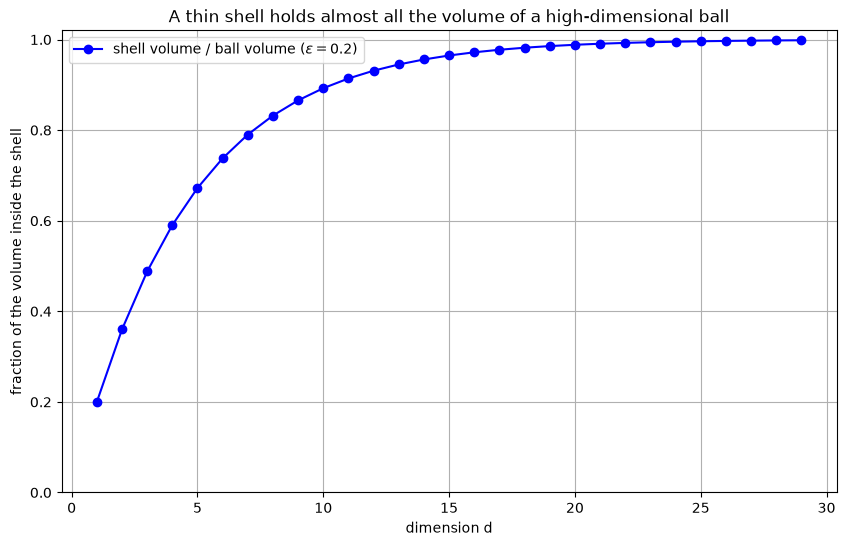

In [2]:
def shell_volume(d, R, e):
    """Volume of the layer R - e < |x| <= R."""
    return hypersphere_volume(d, R) - hypersphere_volume(d, R - e)


dims = list(range(1, 30))
ratio = [shell_volume(d, 1, 0.2) / hypersphere_volume(d, 1) for d in dims]

plt.figure(figsize=(10, 6))
plt.plot(dims, ratio, marker='o', linestyle='-', color='b',
         label=r'shell volume / ball volume ($\epsilon = 0.2$)')
plt.xlabel('dimension d')
plt.ylabel('fraction of the volume inside the shell')
plt.title('A thin shell holds almost all the volume of a high-dimensional ball')
plt.ylim(0, 1.02)
plt.legend()
plt.grid(True)
plt.show()

## Generating Uniform Points on a Hypersphere

Generating points uniformly inside a hypersphere in high dimensions is tricky.
Due to the volume properties discussed above, simple methods like "Rejection Sampling" (generate in cube, keep if in sphere) fail because the acceptance rate approaches zero (remember the Empty Center/Porcupine effect).

**Rejection sampling:** generate points uniformly in the cube $[-1,1]^d$ and keep those inside the unit ball. The acceptance probability is the volume ratio of the ball to the cube:

$$
p_d = \frac{\mathrm{Vol}(B_d(1))}{2^d} = \frac{\pi^{d/2}}{2^d\,\Gamma(d/2+1)},
$$

so $p_2 \approx 0.79$, $p_{10} \approx 0.0025$ and $p_{20} \approx 2.5\times10^{-8}$. Rejection sampling stops being an option well before $d=20$: it is correct, and useless. The next cell measures exactly this.

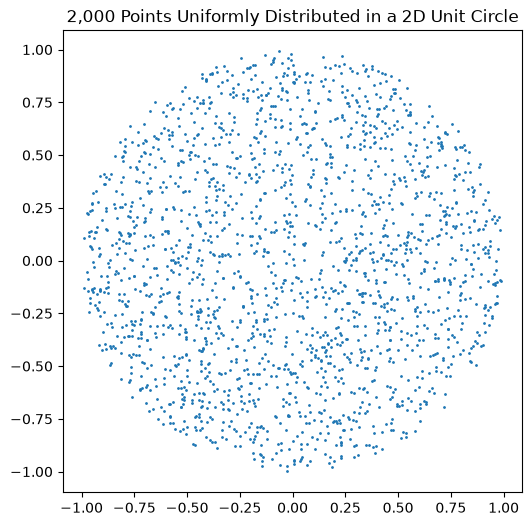

Dimension: 2, Total points generated: 2528, Ratio: 0.7911392405063291
Dimension: 3, Total points generated: 3886, Ratio: 0.514668039114771
Dimension: 4, Total points generated: 6639, Ratio: 0.3012501882813677
Dimension: 5, Total points generated: 12619, Ratio: 0.15849116411760045
Dimension: 6, Total points generated: 24356, Ratio: 0.08211528986697324
Dimension: 7, Total points generated: 54465, Ratio: 0.03672082989075553
Dimension: 8, Total points generated: 126709, Ratio: 0.015784198438942774
Dimension: 9, Total points generated: 307730, Ratio: 0.006499203847528678


Dimension: 10, Total points generated: 784299, Ratio: 0.0025500478771488936


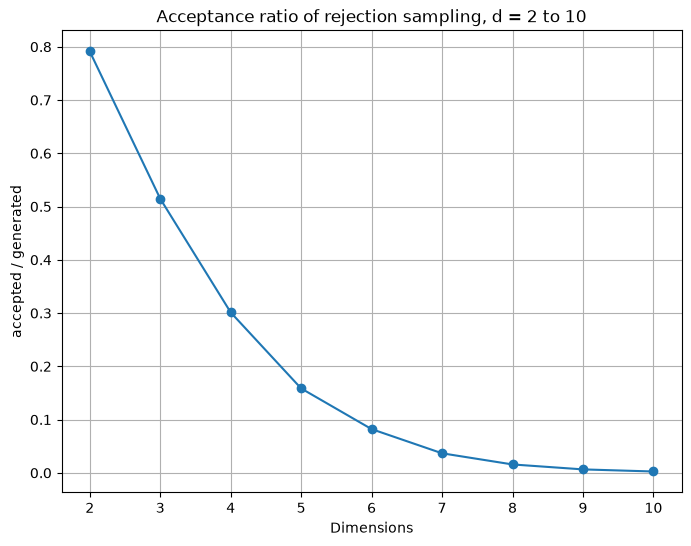

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)          # reproducible figures


# Function to generate num_points points uniformly inside a d-dimensional unit sphere
def generate_points_in_unit_sphere(num_points, d):
    points_inside = []
    total_generated_points = 0  # To track the total number of points generated
    batch_size = num_points  # Initial batch size for generating points
    
    while len(points_inside) < num_points:
        # Generate batch_size points uniformly in the d-dimensional hypercube
        points = np.random.uniform(-1, 1, (batch_size, d))
        
        # Calculate the Euclidean distance of each point from the origin
        distances = np.sum(points**2, axis=1)
        
        # Select points that lie inside the unit sphere
        inside_sphere = points[distances <= 1]
        
        # Append the points inside the sphere to the list
        points_inside.extend(inside_sphere)
        
        # Count total generated points
        total_generated_points += len(points)
        
        # Adjust batch size if we're close to the desired number of points
        remaining_points = num_points - len(points_inside)
        if remaining_points < batch_size:
            batch_size = remaining_points
    
    # Convert the list to a numpy array for efficient storage and manipulation
    points_inside = np.array(points_inside[:num_points])
    
    # acceptance ratio: accepted / generated
    ratio = num_points / total_generated_points
    
    # Return the points inside the sphere and the ratio
    return points_inside, total_generated_points, ratio

# Visualize 2D case
def visualize_2D(points):
    plt.figure(figsize=(6, 6))
    plt.scatter(points[:, 0], points[:, 1], s=1)
    plt.title('2,000 Points Uniformly Distributed in a 2D Unit Circle')
    plt.gca().set_aspect('equal')
    plt.show()

# Generate and visualize points in various dimensions
num_points = 2000
dimensions = list(range(2, 11))  # d from 2 to 10
ratios = []  # To store the ratios for different dimensions

for d in dimensions:
    points_inside, total_generated_points, ratio = generate_points_in_unit_sphere(num_points, d)
    ratios.append(ratio)
    
    if d == 2:
        # For 2D case, visualize the points
        visualize_2D(points_inside)
    
    print(f"Dimension: {d}, Total points generated: {total_generated_points}, Ratio: {ratio}")

# Plot the ratios for dimensions from 2 to 10
plt.figure(figsize=(8, 6))
plt.plot(dimensions, ratios, marker='o')
plt.title('Acceptance ratio of rejection sampling, d = 2 to 10')
plt.xlabel('Dimensions')
plt.ylabel('accepted / generated')
plt.grid(True)
plt.show()



### Generating points from a Gaussian distribution

We now switch from uniform points to Gaussian points, because the multivariate Gaussian is the distribution with no preferred direction: its level sets are spheres.

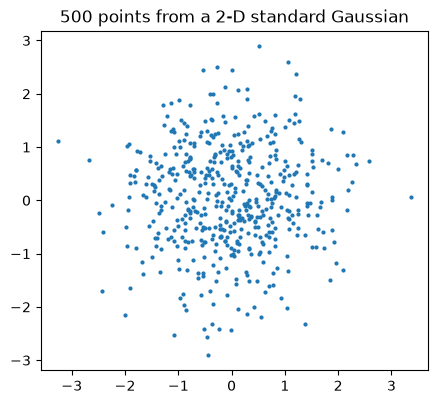

In [4]:
n_points = 500
d = 2
x = np.random.randn(n_points, d)

plt.figure(figsize=(5, 5))
plt.scatter(x[:, 0], x[:, 1], s=4)
plt.title(f'{n_points} points from a {d}-D standard Gaussian')
plt.gca().set_aspect('equal')
plt.show()


### Random vector uniformly distributed on the surface of a unit hypersphere

To generate a random vector $\mathbf{y}$ uniformly distributed on the surface of a unit hypersphere $S_d(1)$:

1.  Generate $x_i \sim \mathcal{N}(0, 1)$ for $i=1 \dots d$.
2.  Normalize: $\mathbf{y} = \frac{\mathbf{x}}{||\mathbf{x}||}$.

This works because the multivariate Gaussian is spherically symmetric.


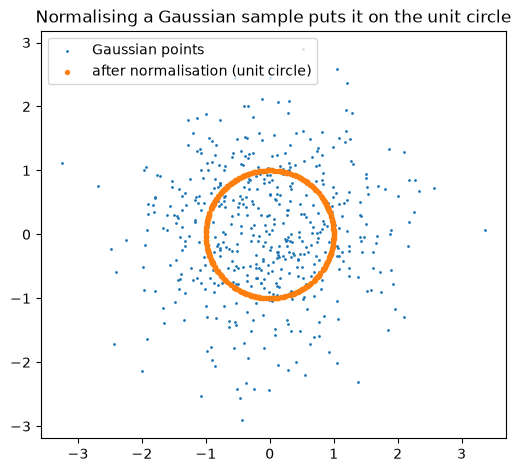

In [5]:
norm_x = np.linalg.norm(x, axis=1)
y = x / norm_x[:, np.newaxis]

plt.figure(figsize=(6, 6))
plt.scatter(x[:, 0], x[:, 1], s=1, label='Gaussian points')
plt.scatter(y[:, 0], y[:, 1], s=8, label='after normalisation (unit circle)')
plt.title('Normalising a Gaussian sample puts it on the unit circle')
plt.legend()
plt.gca().set_aspect('equal')
plt.show()

The joint probability density of the independent Gaussian components is spherically symmetric:

$$ f(x) = \prod_{i=1}^d \frac{1}{\sqrt{2\pi}} e^{-x_i^2/2} = \frac{1}{(2\pi)^{d/2}} e^{-\frac{1}{2}\sum x_i^2} = \frac{1}{(2\pi)^{d/2}} e^{-\frac{||x||^2}{2}} $$

Since the density depends only on the length $||x||$ and not the direction, the direction vectors are uniformly distributed.

**Conclusion:**
The density function $f(\mathbf{x})$ depends **only on the length** (magnitude) of the vector $||\mathbf{x}||$, and not on its coordinates (direction).
* This property is called **Spherical Symmetry** or **Isotropy**.
* It implies that the distribution is invariant under rotation. Therefore, all directions are equally probable, and the normalized vector $\mathbf{y} = \mathbf{x} / ||\mathbf{x}||$ is uniformly distributed on the hypersphere.


### Generating Points *Inside* the Ball

If we want points uniformly distributed *inside* the ball (not just on the surface), the first idea is to take a surface point and scale it by a **uniform** random number $\rho \in [0,1]$:

$$\mathbf{y}=\rho\,\frac{\mathbf{x}}{\lVert\mathbf{x}\rVert}, \qquad \rho \sim \mathcal{U}(0,1).$$

It looks harmless, and it is wrong: it crowds the points near the centre, where the volume is almost nothing. The next cell shows the result, and the sections after it explain the repair.

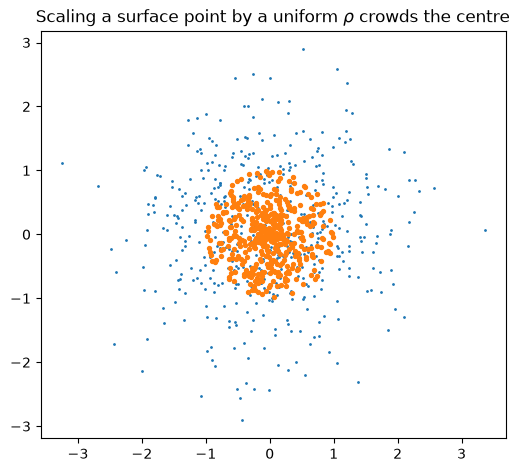

In [6]:
rho = np.random.rand(len(x))
y_naive = rho[:, np.newaxis] * x / norm_x[:, np.newaxis]

plt.figure(figsize=(6, 6))
plt.scatter(x[:, 0], x[:, 1], s=1)
plt.scatter(y_naive[:, 0], y_naive[:, 1], s=8, color='tab:orange')
plt.title(r'Scaling a surface point by a uniform $\rho$ crowds the centre')
plt.gca().set_aspect('equal')
plt.show()

**Why is the naive approach incorrect?**  
If we simply sample the radius $\rho$ uniformly from $[0,1]$, the generated points will cluster near the center.  
In $d$ dimensions, the volume of a thin shell at radius $r$ grows proportionally to $r^{d-1}$.  
This means there is far more volume near the surface ($r \approx 1$) than near the center ($r \approx 0$).  
To achieve a truly uniform distribution inside the ball, the probability of a point lying within radius $r$ must be proportional to the volume enclosed by that radius.

> For uniform volume density, the cumulative distribution function (CDF) must follow the volume growth $r^d$.  
> Thus, we require the random variable $R$ (the radius) to satisfy: $P(R \le r) = r^d.$
> Using Inverse Transform Sampling with $a \sim U(0,1)$, we obtain:  $R = a^{1/d}.$
> A particular sample of $R$ will be denoted by $\rho$.

---

### 1. Determining the Target CDF
Let $R$ denote the random variable representing the radius of a point.  
The cumulative distribution function (CDF), $F(r)$, gives the probability that a point lies within radius $r$:

$$F(r) = P(R \le r).$$

For a uniform distribution inside the $d$‑ball, this probability equals the ratio of the volume of the ball of radius $r$ to the total volume (radius 1):

$$F(r) = \frac{\text{Vol}(S_d(r))}{\text{Vol}(S_d(1))} 
      = \frac{K_d r^d}{K_d \cdot 1^d} 
      = r^d.$$

So our target CDF is simply:

$$F(r) = r^d.$$

---

### 2. Inverse Transform Sampling
How do we generate random radii that follow $F(r) = r^d$?  
We use the **Inverse Transform Sampling** method:

- If $a \sim \mathcal{U}(0,1)$ and $F$ is a continuous CDF, then $X = F^{-1}(a)$ has distribution $F$.  
- Intuitively: we draw a random probability $a$ from $[0,1]$, and ask: *“Which radius $r$ corresponds to this cumulative probability?”*  
- Formally:  If $a \sim U(0,1)$, then $X = F^{-1}(a)$ has distribution $F$:

$$P(X \le R) = P(F^{-1}(a) \le R) = P(a \le F(R)) = F(R).$$

Therefore, if $a \sim \mathcal{U}(0,1)$, then:

$$R = F^{-1}(a) = a^{1/d}.$$

And when we actually generate a sample, we denote it by:

$$\rho = a^{1/d}.$$

---

### 3. Example (for $d=2$)
For a 2‑dimensional ball (a disk), we have:

$$\rho = \sqrt{a}.$$

| $a \sim \mathcal{U}(0,1)$ | $\rho = \sqrt{a}$ |
|--------------------------|---------------------|
| 0.00                     | 0.000               |
| 0.10                     | 0.316               |
| 0.25                     | 0.500               |
| 0.50                     | 0.707               |
| 0.75                     | 0.866               |
| 1.00                     | 1.000               |

This table shows how the transformation spreads points more evenly across the disk, avoiding clustering near the center.

---

### 4. Application to the Hypersphere
Applying this to our radius variable $R$:

1. Generate a uniform random number $a \sim \mathcal{U}(0,1)$.  
2. Compute the radius sample: $\rho = a^{1/d}$.  
3. Combine with a random direction to obtain a point inside the ball.

---

### Algorithm for Uniform Points in a $d$‑Ball
1. Generate a random vector $\mathbf{x} \sim \mathcal{N}(0, I_d)$.  
2. Normalize: $\mathbf{y} = \mathbf{x} / \|\mathbf{x}\|$ (this gives a random direction on the unit sphere).  
3. Generate $a \sim \mathcal{U}(0,1)$.  
4. Scale: $\mathbf{z} = (a^{1/d}) \mathbf{y}$ (this places the point uniformly inside the ball).  


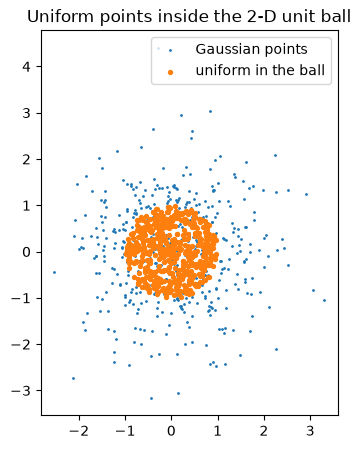

In [7]:
# Uniform points inside a 2-D ball
n_points = 500
d = 2

# 1. Direction: normalise a Gaussian vector (uniform on the sphere)
x = np.random.randn(n_points, d)
norm_x = np.linalg.norm(x, axis=1)
y_surface = x / norm_x[:, np.newaxis]

# 2. Radius: rho = a**(1/d), so that P(R <= r) = r**d
a = np.random.rand(n_points)
rho = a ** (1 / d)
y_inside = rho[:, np.newaxis] * y_surface

plt.figure(figsize=(5, 5))
plt.scatter(x[:, 0], x[:, 1], s=1, label='Gaussian points')
plt.scatter(y_inside[:, 0], y_inside[:, 1], s=8, label='uniform in the ball')
plt.gca().set_aspect('equal')
plt.legend()
plt.title(f'Uniform points inside the {d}-D unit ball')
plt.show()


## Gaussian Distribution in High Dimensions

### From Geometric Thin Shells to Statistical Thin Shells

In previous sections, we saw several geometric phenomena:

* The **Empty Center / Porcupine Effect** in hypercubes (on the theory page)
* The **Thin Shell** inside hyperspheres
* How uniform sampling becomes concentrated near the **surface** rather than the **center**

We also generated uniform points *on* and *inside* a hypersphere and observed that the **volume grows outward**, causing most points to stay away from the center.

Now we show that **Gaussian data behave in exactly the same way** — even though the Gaussian distribution is centered at the origin.

---

## Why Gaussian Points Do *Not* Cluster Near the Mean (Unlike 1D)

Let
$ x = (x_1,\dots,x_d) \sim \mathcal{N}(0, I_d) $.

In one dimension, many sampled points lie “close to zero,” and the distance $|x|$ is usually small.
However, this intuition **completely breaks down** as soon as we move to dimension 2 or higher.

The key difference is **geometry**:

* In 1D, “the center” is just a point, and the line has no notion of volume growth.
* In higher dimensions, **volume explodes with radius**:

  * Area $\propto r^2$
  * Volume $\propto r^3$
  * In general: hypersphere volume $\propto r^{d}$

Thus, although the Gaussian **density** is highest at the origin, the **available volume** near the origin is vanishingly small.

> **The center has the highest density but almost zero volume $\Rightarrow$ almost no sampled points appear there.**

This exactly mirrors the thin-shell phenomenon you observed for uniform sampling.

---

## Distance of a Gaussian Vector from the Origin

A central identity explains the behavior:

$$|x|^2 = \sum_{i=1}^d x_i^2 \sim \chi^2_d$$

Thus (See [Chi-squared distribution](https://en.wikipedia.org/wiki/Chi-squared_distribution)):

$$\mathbb{E}[|x|^2] = d \qquad\Rightarrow\qquad \mathbb{E}[|x|] \approx \sqrt{d}.$$

* In 1D: $|x| \approx 0.8$ (close to the center)
* In 2D: $|x| \approx \sqrt{2} \approx 1.41$
* In 10D: $|x| \approx \sqrt{10} \approx 3.16$
* In 200D: $|x| \approx \sqrt{200} \approx 14.1$

And importantly:

> **Increasing dimension pushes *all* Gaussian samples outward, not just a few outliers.
> Almost the entire distribution lies in a thin spherical shell around radius $\sqrt{d}$.**

This is the statistical analogue of the geometric thin-shell effect.

---

## Numerical Simulation: Gaussian Thin Shell

<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2698829/2529169885.py:26: SyntaxWarning: invalid escape sequence '\s'
  ax[1].set_title(f"{d}-D Gaussian: Mass at Tail ($\sqrt{{d}}$)")
/tmp/ipykernel_2698829/2529169885.py:28: SyntaxWarning: invalid escape sequence '\s'
  ax[1].axvline(np.sqrt(d), color='red', linestyle='--', label='$\sqrt{d} \\approx 14.1$')


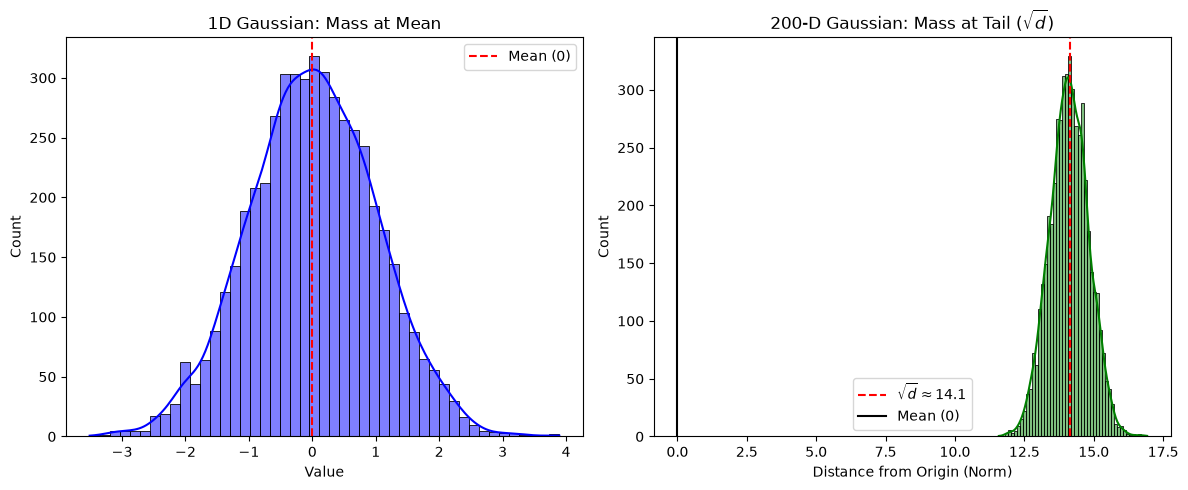

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Simulation: 1D vs High-D Gaussian
d = 200
n_samples = 5000

# 1D Gaussian
x_1d = np.random.randn(n_samples)

# High-D Gaussian
x_high = np.random.randn(n_samples, d)
norm_x_high = np.linalg.norm(x_high, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: 1D behavior
sns.histplot(x_1d, kde=True, ax=ax[0], color='blue')
ax[0].set_title("1D Gaussian: Mass at Mean")
ax[0].set_xlabel("Value")
ax[0].axvline(0, color='red', linestyle='--', label='Mean (0)')

# Plot 2: High-D behavior
sns.histplot(norm_x_high, kde=True, ax=ax[1], color='green')
ax[1].set_title(f"{d}-D Gaussian: Mass at Tail ($\sqrt{{d}}$)")
ax[1].set_xlabel("Distance from Origin (Norm)")
ax[1].axvline(np.sqrt(d), color='red', linestyle='--', label='$\sqrt{d} \\approx 14.1$')
ax[1].axvline(0, color='black', linestyle='-', label='Mean (0)')

ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

These two plots illustrate the fundamental shift from “mass at center” (low dimension) to “mass in a thin shell” (high dimension).

---

## The Gaussian Annulus Phenomenon

A formal version states:

> With overwhelming probability, a Gaussian sample lies inside
> $ \sqrt{d} \pm O(1) $
> — a thin annulus whose thickness does *not* grow with $d$.

As $d$ increases:

* Radius grows like $\sqrt{d}$
* Shell thickness remains constant
* Relative shell thickness $\rightarrow$ 0

So the Gaussian distribution becomes **extremely concentrated** on a thin spherical layer.

This mirrors exactly what we saw earlier for:

* Uniform points inside a hypersphere
* Rejection sampling
* Volume concentration
* Empty Center effect

This is why Gaussian distributions are used so heavily in theory:
they reflect the **intrinsic geometry of high-dimensional space**.

---

## Connection to Previous Sections

Here is how the Gaussian phenomenon links back to the concepts earlier in the notebook:

**Relation to “Empty Center / Porcupine Effect”**

Volume around the center is negligible in high dimensions $\rightarrow$
**Gaussian mass avoids the center**, exactly like uniform points.

---

**Relation to “Thin Shell Argument”**

Uniform hypersphere volume concentrates at radius $r$:
Gaussian probability mass concentrates at radius $\sqrt{d}$.
The geometry is identical; only the radius scale differs.

---

**Relation to “Generating Points Inside the Ball”**

You observed that uniform points require special sampling ($\rho = a^{1/d}$)
because naive sampling bunches points near the center.

Gaussian sampling naturally avoids the center due to the same volume effects.

---

**Relation to “Random Vectors are Nearly Orthogonal”**

Since nearly all Gaussian points lie at distance $\sqrt{d}$,
their normalized directions behave almost like points uniformly distributed on the sphere.

Thus Gaussian vectors are almost orthogonal —
the basis for **random projection** and **Johnson–Lindenstrauss**.

---

## Why This Matters (Preparing for JL)

Gaussian thin-shell concentration ensures:

* Pairwise distances are stable
* Dot products are small
* Random projections preserve geometry

These facts are exactly what the **Johnson–Lindenstrauss Lemma** formalizes.

This section therefore serves as the **bridge** from geometric properties of high-dimensional space to the theoretical foundation of dimensionality reduction.


## Summary

* The volume of a ball of radius $1-\epsilon$ is $(1-\epsilon)^d$ of the whole
  ball, so for $d=100$ a $1\%$ peel holds $63\%$ of the volume: the centre is empty.
* Rejection sampling accepts a cube point with probability
  $p_d=\pi^{d/2}/(2^d\Gamma(d/2+1))$, which is $2.5\times10^{-8}$ at $d=20$:
  correct, and useless.
* Normalising a Gaussian vector gives a uniform direction on the sphere, because
  the Gaussian density depends only on the length of the vector.
* For a uniform point inside the ball the radius must satisfy
  $\mathbb{P}(R\le r)=r^d$, hence $\rho=a^{1/d}$ with $a\sim\mathcal{U}(0,1)$;
  scaling by a uniform $\rho$ without the root crowds the centre.
* A Gaussian sample in $d$ dimensions sits in a shell of radius $\sqrt{d}$ whose
  thickness does not grow with $d$ — the geometric fact behind the
  [Johnson–Lindenstrauss lemma](Random-Projection.ipynb).

## Exercises

1. For $d=10$ and $\epsilon=0.01$, what fraction of the volume of the unit ball
   lies in the shell $0.99<r\le1$? Check the number with `shell_volume`.
2. Measure the acceptance ratio of rejection sampling for $d=2,\ldots,12$ and
   compare it with $p_d$. At which $d$ does it fall below $1\%$?
3. Generate $10^4$ points with $\rho=a^{1/d}$ for $d=2$ and $d=5$ and plot the
   histogram of $\lVert x\rVert$. Where is the mode, and what does the theory
   predict?
4. Keep the Gaussian radius but replace the direction by a random $\pm1$ vector
   (signs of Gaussian coordinates). Are the points still uniform on the sphere?
   Explain what you see.
5. Simulate Gaussian samples for $d=10,100,1000$ and measure the standard deviation
   of $\lVert x\rVert$. The $\chi^2$ identity gives variance $2d$ for
   $\lVert x\rVert^2$, i.e. about $1/\sqrt{2}$ for $\lVert x\rVert$. Check it.

## Sources

- A. Blum, J. Hopcroft, R. Kannan, *Foundations of Data Science*, the sections on
  sampling in high dimension and the thin shell.
- {cite}`zaki2020data`, Ch. 6 (figures reused on the theory page).
